***This is a contribution toward a group project. The code below is produced by me, but data acquisition, some data preprocessing and other steps were completed by other members of the group: Brad Henry, Chris Mayo, Toye Oloko, Brady Rothrock, and Chris Wong.***

### Data import and processing

**Import dependencies**

In [1]:
# Dependencies

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn import tree

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

**Import DataFrame**

In [2]:
pd.set_option('display.max_columns', None)
summarized_df = pd.read_csv("summarized_df_all.csv")
summarized_df.head()

,gameId,playId,passResult,playResult,defendersInBox,dropBackType,pff_playAction,pff_passCoverage,pff_passCoverageType,Avg Pass Block Dist,Avg Pass Rush Dist,Total Pass Block Dist,Total Pass Rush Dist,Count Pass Blockers,Count Pass Rushers,QB Hurry,QB Hit,QB Sack,Net Avg Dist,Net Total Dist,Net Count,distance mean offense,distance min offense,velocity mean offense,velocity min offense,acceleration mean offense,acceleration min offense,distance mean defense,distance min defense,velocity mean defense,velocity min defense,acceleration mean defense,acceleration min defense
0,2021090900,97,I,0,6.0,TRADITIONAL,0,Cover-1,Man,4.445453,7.406640,22.227265,37.033198,5.0,5.0,1.0,0.0,0.0,2.961187,14.805933,0.0,3.431727,2.408402,-0.117657,-0.307823,-0.011442,-0.154471,3.775175,2.264509,-0.198693,-0.415884,-0.020134,-0.140042
1,2021090900,137,C,28,6.0,TRADITIONAL,0,Cover-3,Zone,4.344564,7.225690,21.722820,36.128452,5.0,5.0,0.0,0.0,0.0,2.881126,14.405632,0.0,3.502839,2.705587,-0.116613,-0.254739,-0.017271,-0.091075,4.064741,2.602499,-0.428310,-0.478576,-0.011256,-0.053059
2,2021090900,187,C,5,6.0,TRADITIONAL,0,Cover-3,Zone,3.867940,7.022646,19.339700,28.090584,5.0,4.0,0.0,0.0,0.0,3.154706,8.750883,1.0,3.362039,3.299470,-0.058842,-0.153910,-0.028639,-0.058962,5.001080,4.729588,-0.335822,-0.385178,-0.014268,-0.066291
3,2021090900,349,I,0,7.0,TRADITIONAL,0,Cover-3,Zone,3.476340,6.762694,20.858042,33.813471,6.0,5.0,1.0,1.0,0.0,3.286354,12.955429,1.0,2.834510,2.068647,-0.173138,-0.316397,-0.026172,-0.072769,2.860401,1.516080,-0.302427,-0.384111,-0.011750,-0.048176
4,2021090900,410,C,10,6.0,TRADITIONAL,0,Cover-1,Man,4.008327,6.668074,20.041634,33.340370,5.0,5.0,0.0,0.0,0.0,2.659747,13.298736,0.0,3.250858,2.808630,-0.216272,-0.228622,-0.038100,-0.065866,4.247331,3.758005,-0.370200,-0.379882,-0.021323,-0.054931


**Inspect DataFrame**

In [3]:
print('Number of NaN values per column:\n', summarized_df.isna().sum(), '\n')
print('Dataframe shape:\n', np.shape(summarized_df), '\n')
print('Number of unique player IDs:\n', len(summarized_df.playId.unique()), '\n')
#print('Number of unique game IDs:\n', summarized_df.gameId.unique(), '\n')
print('List of dropback types:\n', summarized_df.dropBackType.unique(), '\n')

Number of NaN values per column:
 gameId                         0
playId                         0
passResult                     0
playResult                     0
defendersInBox                 2
dropBackType                  46
pff_playAction                 0
pff_passCoverage               0
pff_passCoverageType           0
Avg Pass Block Dist            0
Avg Pass Rush Dist             0
Total Pass Block Dist          0
Total Pass Rush Dist           0
Count Pass Blockers            0
Count Pass Rushers             0
QB Hurry                       0
QB Hit                         0
QB Sack                        0
Net Avg Dist                   0
Net Total Dist                 0
Net Count                      0
distance mean offense          0
distance min offense           0
velocity mean offense        386
velocity min offense         386
acceleration mean offense    733
acceleration min offense     733
distance mean defense          0
distance min defense           0
velocity 

**Drop NaNs and inspect resulting DataFrame**

In [4]:
no_nan_df = summarized_df.dropna().copy()
print('Shape of Dataframe after removing rows with NaNs:\n', np.shape(no_nan_df), '\n')
print('List of pass coverage types:\n', no_nan_df.pff_passCoverageType.unique(), '\n')

Shape of Dataframe after removing rows with NaNs:
 (6704, 33) 

List of pass coverage types:
 ['Man' 'Zone' 'Other'] 



In [5]:
no_nan_df.head()

,gameId,playId,passResult,playResult,defendersInBox,dropBackType,pff_playAction,pff_passCoverage,pff_passCoverageType,Avg Pass Block Dist,Avg Pass Rush Dist,Total Pass Block Dist,Total Pass Rush Dist,Count Pass Blockers,Count Pass Rushers,QB Hurry,QB Hit,QB Sack,Net Avg Dist,Net Total Dist,Net Count,distance mean offense,distance min offense,velocity mean offense,velocity min offense,acceleration mean offense,acceleration min offense,distance mean defense,distance min defense,velocity mean defense,velocity min defense,acceleration mean defense,acceleration min defense
0,2021090900,97,I,0,6.0,TRADITIONAL,0,Cover-1,Man,4.445453,7.406640,22.227265,37.033198,5.0,5.0,1.0,0.0,0.0,2.961187,14.805933,0.0,3.431727,2.408402,-0.117657,-0.307823,-0.011442,-0.154471,3.775175,2.264509,-0.198693,-0.415884,-0.020134,-0.140042
1,2021090900,137,C,28,6.0,TRADITIONAL,0,Cover-3,Zone,4.344564,7.225690,21.722820,36.128452,5.0,5.0,0.0,0.0,0.0,2.881126,14.405632,0.0,3.502839,2.705587,-0.116613,-0.254739,-0.017271,-0.091075,4.064741,2.602499,-0.428310,-0.478576,-0.011256,-0.053059
2,2021090900,187,C,5,6.0,TRADITIONAL,0,Cover-3,Zone,3.867940,7.022646,19.339700,28.090584,5.0,4.0,0.0,0.0,0.0,3.154706,8.750883,1.0,3.362039,3.299470,-0.058842,-0.153910,-0.028639,-0.058962,5.001080,4.729588,-0.335822,-0.385178,-0.014268,-0.066291
3,2021090900,349,I,0,7.0,TRADITIONAL,0,Cover-3,Zone,3.476340,6.762694,20.858042,33.813471,6.0,5.0,1.0,1.0,0.0,3.286354,12.955429,1.0,2.834510,2.068647,-0.173138,-0.316397,-0.026172,-0.072769,2.860401,1.516080,-0.302427,-0.384111,-0.011750,-0.048176
4,2021090900,410,C,10,6.0,TRADITIONAL,0,Cover-1,Man,4.008327,6.668074,20.041634,33.340370,5.0,5.0,0.0,0.0,0.0,2.659747,13.298736,0.0,3.250858,2.808630,-0.216272,-0.228622,-0.038100,-0.065866,4.247331,3.758005,-0.370200,-0.379882,-0.021323,-0.054931


**Numerically encode categorical data**

In [6]:
no_nan_df['passResult_code'] = no_nan_df['passResult'].apply(lambda x: ['I', 'C', 'S', 'R', 'IN'].index(x))
no_nan_df['dropBackType_code'] = no_nan_df['dropBackType'].apply(lambda x: ['TRADITIONAL', 'SCRAMBLE_ROLLOUT_RIGHT', 'DESIGNED_ROLLOUT_RIGHT', 'SCRAMBLE_ROLLOUT_LEFT', 'DESIGNED_ROLLOUT_LEFT', 'DESIGNED_RUN', 'SCRAMBLE', 'UNKNOWN'].index(x))
no_nan_df['pff_passCoverage_code'] = no_nan_df['pff_passCoverage'].apply(lambda x: ['Cover-0', 'Cover-1', 'Cover-2', 'Cover-3', 'Cover-6', 'Quarters', '2-Man', 'Prevent', 'Bracket', 'Red Zone', 'Miscellaneous', 'Goal Line'].index(x))
no_nan_df['pff_passCoverageType_code'] = no_nan_df['pff_passCoverageType'].apply(lambda x: ['Man', 'Zone', 'Other'].index(x))
no_nan_df

,gameId,playId,passResult,playResult,defendersInBox,dropBackType,pff_playAction,pff_passCoverage,pff_passCoverageType,Avg Pass Block Dist,Avg Pass Rush Dist,Total Pass Block Dist,Total Pass Rush Dist,Count Pass Blockers,Count Pass Rushers,QB Hurry,QB Hit,QB Sack,Net Avg Dist,Net Total Dist,Net Count,distance mean offense,distance min offense,velocity mean offense,velocity min offense,acceleration mean offense,acceleration min offense,distance mean defense,distance min defense,velocity mean defense,velocity min defense,acceleration mean defense,acceleration min defense,passResult_code,dropBackType_code,pff_passCoverage_code,pff_passCoverageType_code
0,2021090900,97,I,0,6.0,TRADITIONAL,0,Cover-1,Man,4.445453,7.406640,22.227265,37.033198,5.0,5.0,1.0,0.0,0.0,2.961187,14.805933,0.0,3.431727,2.408402,-0.117657,-0.307823,-0.011442,-0.154471,3.775175,2.264509,-0.198693,-0.415884,-0.020134,-0.140042,0,0,1,0
1,2021090900,137,C,28,6.0,TRADITIONAL,0,Cover-3,Zone,4.344564,7.225690,21.722820,36.128452,5.0,5.0,0.0,0.0,0.0,2.881126,14.405632,0.0,3.502839,2.705587,-0.116613,-0.254739,-0.017271,-0.091075,4.064741,2.602499,-0.428310,-0.478576,-0.011256,-0.053059,1,0,3,1
2,2021090900,187,C,5,6.0,TRADITIONAL,0,Cover-3,Zone,3.867940,7.022646,19.339700,28.090584,5.0,4.0,0.0,0.0,0.0,3.154706,8.750883,1.0,3.362039,3.299470,-0.058842,-0.153910,-0.028639,-0.058962,5.001080,4.729588,-0.335822,-0.385178,-0.014268,-0.066291,1,0,3,1
3,2021090900,349,I,0,7.0,TRADITIONAL,0,Cover-3,Zone,3.476340,6.762694,20.858042,33.813471,6.0,5.0,1.0,1.0,0.0,3.286354,12.955429,1.0,2.834510,2.068647,-0.173138,-0.316397,-0.026172,-0.072769,2.860401,1.516080,-0.302427,-0.384111,-0.011750,-0.048176,0,0,3,1
4,2021090900,410,C,10,6.0,TRADITIONAL,0,Cover-1,Man,4.008327,6.668074,20.041634,33.340370,5.0,5.0,0.0,0.0,0.0,2.659747,13.298736,0.0,3.250858,2.808630,-0.216272,-0.228622,-0.038100,-0.065866,4.247331,3.758005,-0.370200,-0.379882,-0.021323,-0.054931,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7471,2021110100,4310,S,-8,4.0,SCRAMBLE,0,Bracket,Other,4.285241,7.340940,21.426204,22.022819,5.0,3.0,0.0,0.0,1.0,3.055699,0.596615,2.0,4.241146,2.281272,0.000790,-0.330421,0.001156,-0.098499,4.750581,3.142006,-0.059640,-0.288957,0.002007,-0.057433,2,6,8,2
7472,2021110100,4363,C,3,5.0,SCRAMBLE,0,Cover-2,Zone,4.295539,7.298670,21.477696,29.194678,5.0,4.0,1.0,0.0,0.0,3.003130,7.716983,1.0,3.550136,2.326478,-0.083624,-0.247969,-0.001935,-0.054100,4.154523,2.699481,-0.145385,-0.282823,-0.006104,-0.084644,1,6,2,1
7473,2021110100,4392,S,-8,6.0,TRADITIONAL,0,Cover-2,Zone,4.260286,6.749210,21.301432,20.247631,5.0,3.0,1.0,0.0,1.0,2.488924,-1.053801,2.0,2.717868,0.431741,-0.065434,-0.388328,-0.013808,-0.078669,3.243022,0.971700,-0.108380,-0.378664,0.007536,-0.069001,2,0,2,1
7474,2021110100,4411,I,0,5.0,TRADITIONAL,0,Cover-2,Zone,3.900383,7.343761,23.402297,36.718805,6.0,5.0,1.0,0.0,0.0,3.443378,13.316507,1.0,1.876794,1.603652,-0.120985,-0.172195,-0.013166,-0.062803,4.695366,2.248044,-0.367649,-0.460447,-0.023002,-0.085945,0,0,2,1


**Drop (now redundant) categorical data**

In [7]:
X = no_nan_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB Hurry', 'QB Hit', 'QB Sack'])
X

,gameId,playId,playResult,defendersInBox,pff_playAction,Avg Pass Block Dist,Avg Pass Rush Dist,Total Pass Block Dist,Total Pass Rush Dist,Count Pass Blockers,Count Pass Rushers,Net Avg Dist,Net Total Dist,Net Count,distance mean offense,distance min offense,velocity mean offense,velocity min offense,acceleration mean offense,acceleration min offense,distance mean defense,distance min defense,velocity mean defense,velocity min defense,acceleration mean defense,acceleration min defense,passResult_code,dropBackType_code,pff_passCoverage_code,pff_passCoverageType_code
0,2021090900,97,0,6.0,0,4.445453,7.406640,22.227265,37.033198,5.0,5.0,2.961187,14.805933,0.0,3.431727,2.408402,-0.117657,-0.307823,-0.011442,-0.154471,3.775175,2.264509,-0.198693,-0.415884,-0.020134,-0.140042,0,0,1,0
1,2021090900,137,28,6.0,0,4.344564,7.225690,21.722820,36.128452,5.0,5.0,2.881126,14.405632,0.0,3.502839,2.705587,-0.116613,-0.254739,-0.017271,-0.091075,4.064741,2.602499,-0.428310,-0.478576,-0.011256,-0.053059,1,0,3,1
2,2021090900,187,5,6.0,0,3.867940,7.022646,19.339700,28.090584,5.0,4.0,3.154706,8.750883,1.0,3.362039,3.299470,-0.058842,-0.153910,-0.028639,-0.058962,5.001080,4.729588,-0.335822,-0.385178,-0.014268,-0.066291,1,0,3,1
3,2021090900,349,0,7.0,0,3.476340,6.762694,20.858042,33.813471,6.0,5.0,3.286354,12.955429,1.0,2.834510,2.068647,-0.173138,-0.316397,-0.026172,-0.072769,2.860401,1.516080,-0.302427,-0.384111,-0.011750,-0.048176,0,0,3,1
4,2021090900,410,10,6.0,0,4.008327,6.668074,20.041634,33.340370,5.0,5.0,2.659747,13.298736,0.0,3.250858,2.808630,-0.216272,-0.228622,-0.038100,-0.065866,4.247331,3.758005,-0.370200,-0.379882,-0.021323,-0.054931,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7471,2021110100,4310,-8,4.0,0,4.285241,7.340940,21.426204,22.022819,5.0,3.0,3.055699,0.596615,2.0,4.241146,2.281272,0.000790,-0.330421,0.001156,-0.098499,4.750581,3.142006,-0.059640,-0.288957,0.002007,-0.057433,2,6,8,2
7472,2021110100,4363,3,5.0,0,4.295539,7.298670,21.477696,29.194678,5.0,4.0,3.003130,7.716983,1.0,3.550136,2.326478,-0.083624,-0.247969,-0.001935,-0.054100,4.154523,2.699481,-0.145385,-0.282823,-0.006104,-0.084644,1,6,2,1
7473,2021110100,4392,-8,6.0,0,4.260286,6.749210,21.301432,20.247631,5.0,3.0,2.488924,-1.053801,2.0,2.717868,0.431741,-0.065434,-0.388328,-0.013808,-0.078669,3.243022,0.971700,-0.108380,-0.378664,0.007536,-0.069001,2,0,2,1
7474,2021110100,4411,0,5.0,0,3.900383,7.343761,23.402297,36.718805,6.0,5.0,3.443378,13.316507,1.0,1.876794,1.603652,-0.120985,-0.172195,-0.013166,-0.062803,4.695366,2.248044,-0.367649,-0.460447,-0.023002,-0.085945,0,0,2,1


**Remove spaces in column names, produce input DataFrames, produce target vectors**

In [8]:
underscores_df = no_nan_df
underscores_df.columns = [c.replace(' ', '_') for c in underscores_df.columns]
underscores_df

X_hurry = underscores_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB_Hurry'])
X_hit = underscores_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB_Hit'])
X_sack = underscores_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB_Sack'])

y_hurry = underscores_df.QB_Hurry
y_hit = underscores_df.QB_Hit
y_sack = underscores_df.QB_Sack

### Random Forests and Feature Importance Analysis

#### Predicting a hurry

**Split data into training and testing sets**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X_hurry, y_hurry, test_size = 0.2, random_state = 8)

hurry_forest = RandomForestClassifier(n_estimators=100) #Creates the forest
hurry_forest = hurry_forest.fit(X_train,y_train) #Fits the forest to the data

hurry_importances = hurry_forest.feature_importances_ #Feature importances, note the underscore
hurry_importances

array([0.01888646, 0.02961541, 0.02521772, 0.01032057, 0.00312329,
       0.03053643, 0.03167019, 0.02884193, 0.03204961, 0.00462877,
       0.00576631, 0.00755124, 0.00311259, 0.02930794, 0.03151231,
       0.00636792, 0.03753031, 0.06159797, 0.04746443, 0.04142372,
       0.05131048, 0.03585806, 0.04848589, 0.12961259, 0.03730482,
       0.06197427, 0.03537979, 0.03755879, 0.01136368, 0.04523074,
       0.0141024 , 0.00529336])

In [10]:
y_predicted = hurry_forest.predict(X_test)
y_predicted

array([0., 1., 0., ..., 0., 0., 0.])

**Confusion matrix**

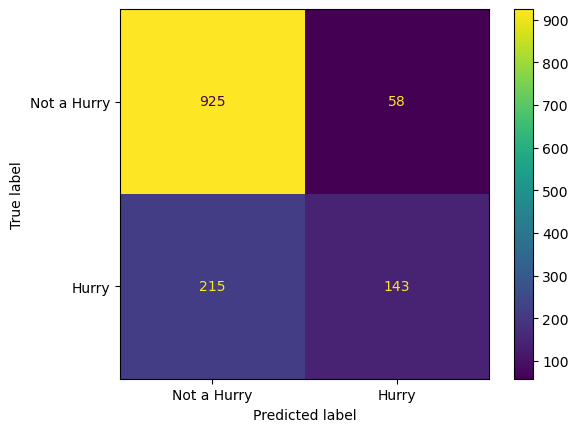

In [11]:
c_matrix = confusion_matrix(y_test,y_predicted)
c_matrix

hurry_labels = np.array(['Not a Hurry', 'Hurry'])
disp = ConfusionMatrixDisplay(confusion_matrix = c_matrix, display_labels = hurry_labels)
disp.plot()
plt.show()

**Classification report**

In [12]:
hurry_class_report = classification_report(y_test, y_predicted, target_names=hurry_labels)
print(hurry_class_report)

              precision    recall  f1-score   support

 Not a Hurry       0.81      0.94      0.87       983
       Hurry       0.71      0.40      0.51       358

    accuracy                           0.80      1341
   macro avg       0.76      0.67      0.69      1341
weighted avg       0.78      0.80      0.78      1341



**Show relative feature importance**

<Axes: >

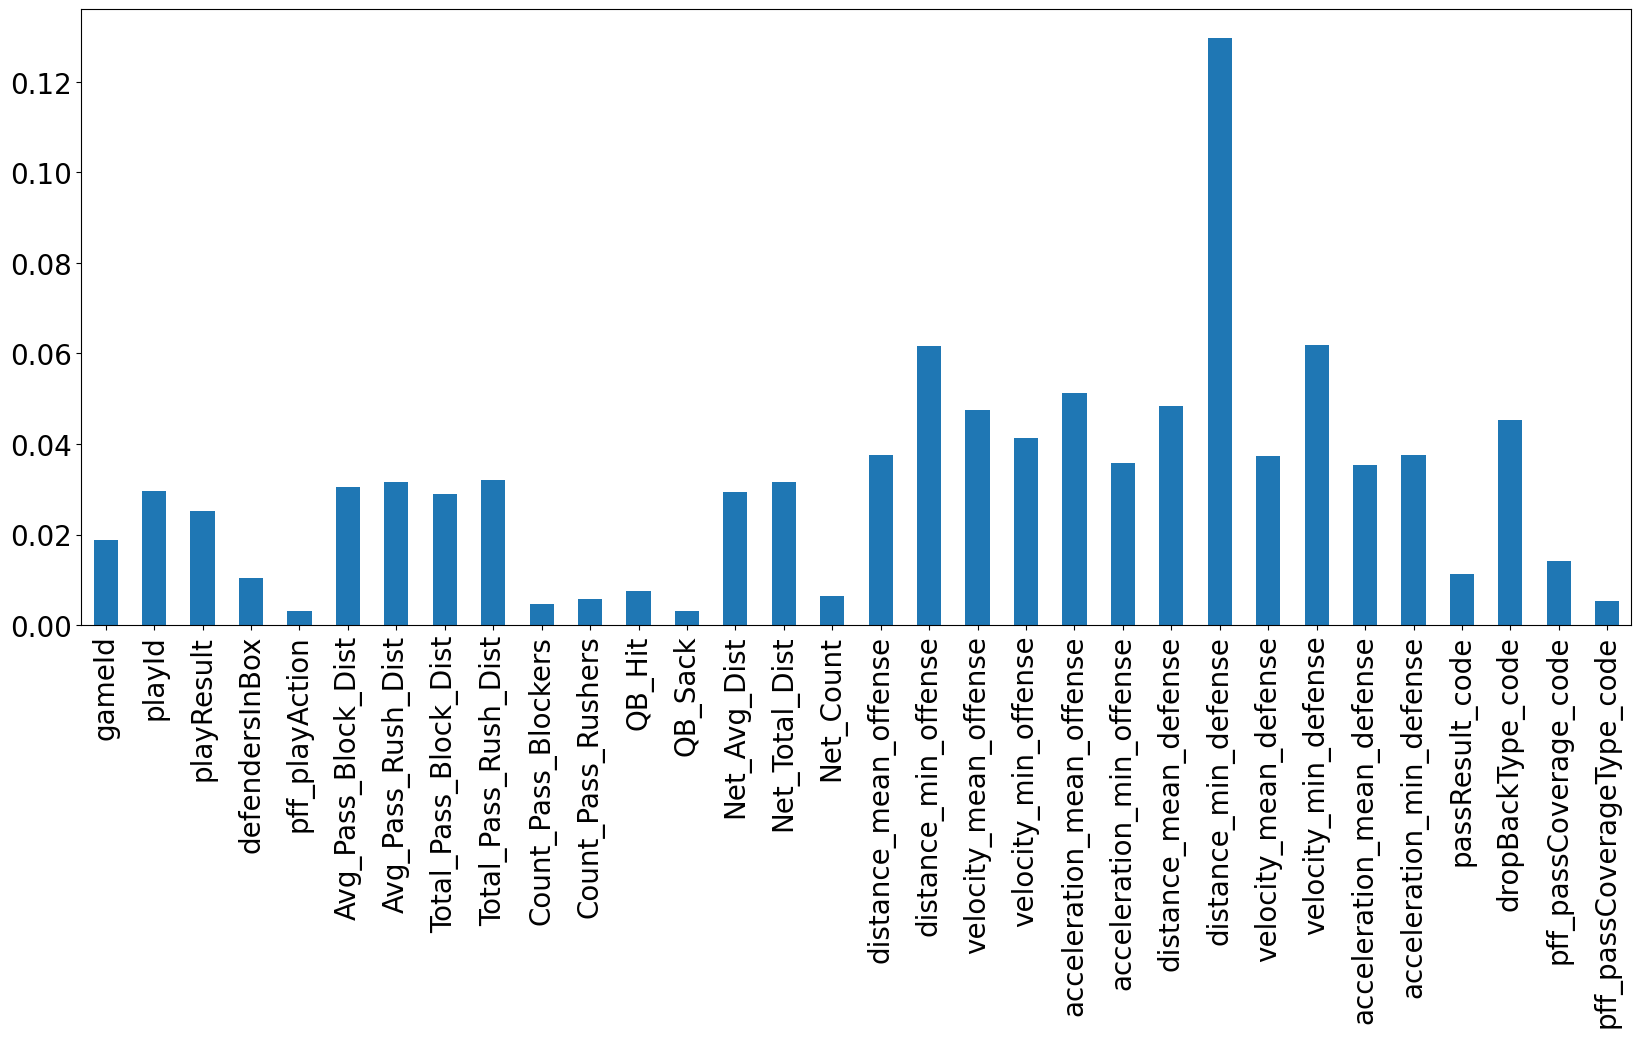

In [13]:
hurry_forest_importances = pd.Series(hurry_importances, index=X_train.columns) #This makes the feature names the axis labels
hurry_forest_importances.plot.bar(fontsize=20, figsize=(20,8))

#### Predicting a hit

**Split data into training and testing sets**

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_hit, y_hit, test_size = 0.2, random_state = 8)

hit_forest = RandomForestClassifier(n_estimators=100) #Creates the forest
hit_forest = hit_forest.fit(X_train,y_train) #Fits the forest to the data

hit_importances = hit_forest.feature_importances_ #Feature importances, note the underscore
hit_importances

array([0.02193501, 0.03525581, 0.03000065, 0.01137193, 0.00237689,
       0.03555361, 0.03338086, 0.03249102, 0.03326503, 0.00429196,
       0.00605697, 0.02028398, 0.01103027, 0.03473029, 0.03215981,
       0.00781767, 0.03720696, 0.04903262, 0.03395385, 0.0386993 ,
       0.03917338, 0.04002434, 0.05043487, 0.12011927, 0.04335736,
       0.06086302, 0.03733111, 0.04190161, 0.02852214, 0.00457122,
       0.01724621, 0.00556096])

In [15]:
y_predicted = hit_forest.predict(X_test)
y_predicted

array([0., 0., 0., ..., 0., 0., 0.])

**Confusion matrix, classification report, and feature importance**

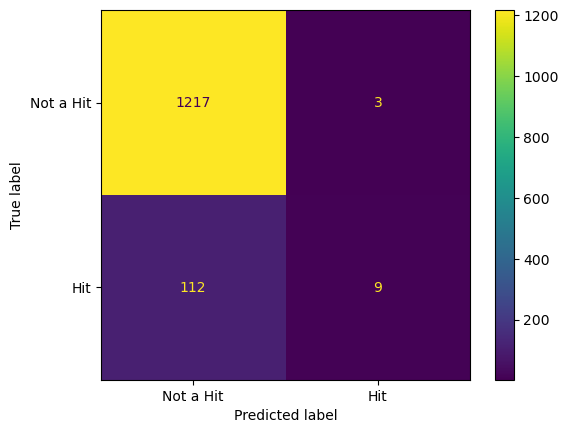

In [16]:
c_hit_matrix = confusion_matrix(y_test,y_predicted)
c_hit_matrix

hit_labels = np.array(['Not a Hit', 'Hit'])
disp = ConfusionMatrixDisplay(confusion_matrix = c_hit_matrix, display_labels = hit_labels)
disp.plot()
plt.show()

In [17]:
hit_class_report = classification_report(y_test, y_predicted, target_names=hit_labels)
print(hit_class_report)

              precision    recall  f1-score   support

   Not a Hit       0.92      1.00      0.95      1220
         Hit       0.75      0.07      0.14       121

    accuracy                           0.91      1341
   macro avg       0.83      0.54      0.55      1341
weighted avg       0.90      0.91      0.88      1341



<Axes: >

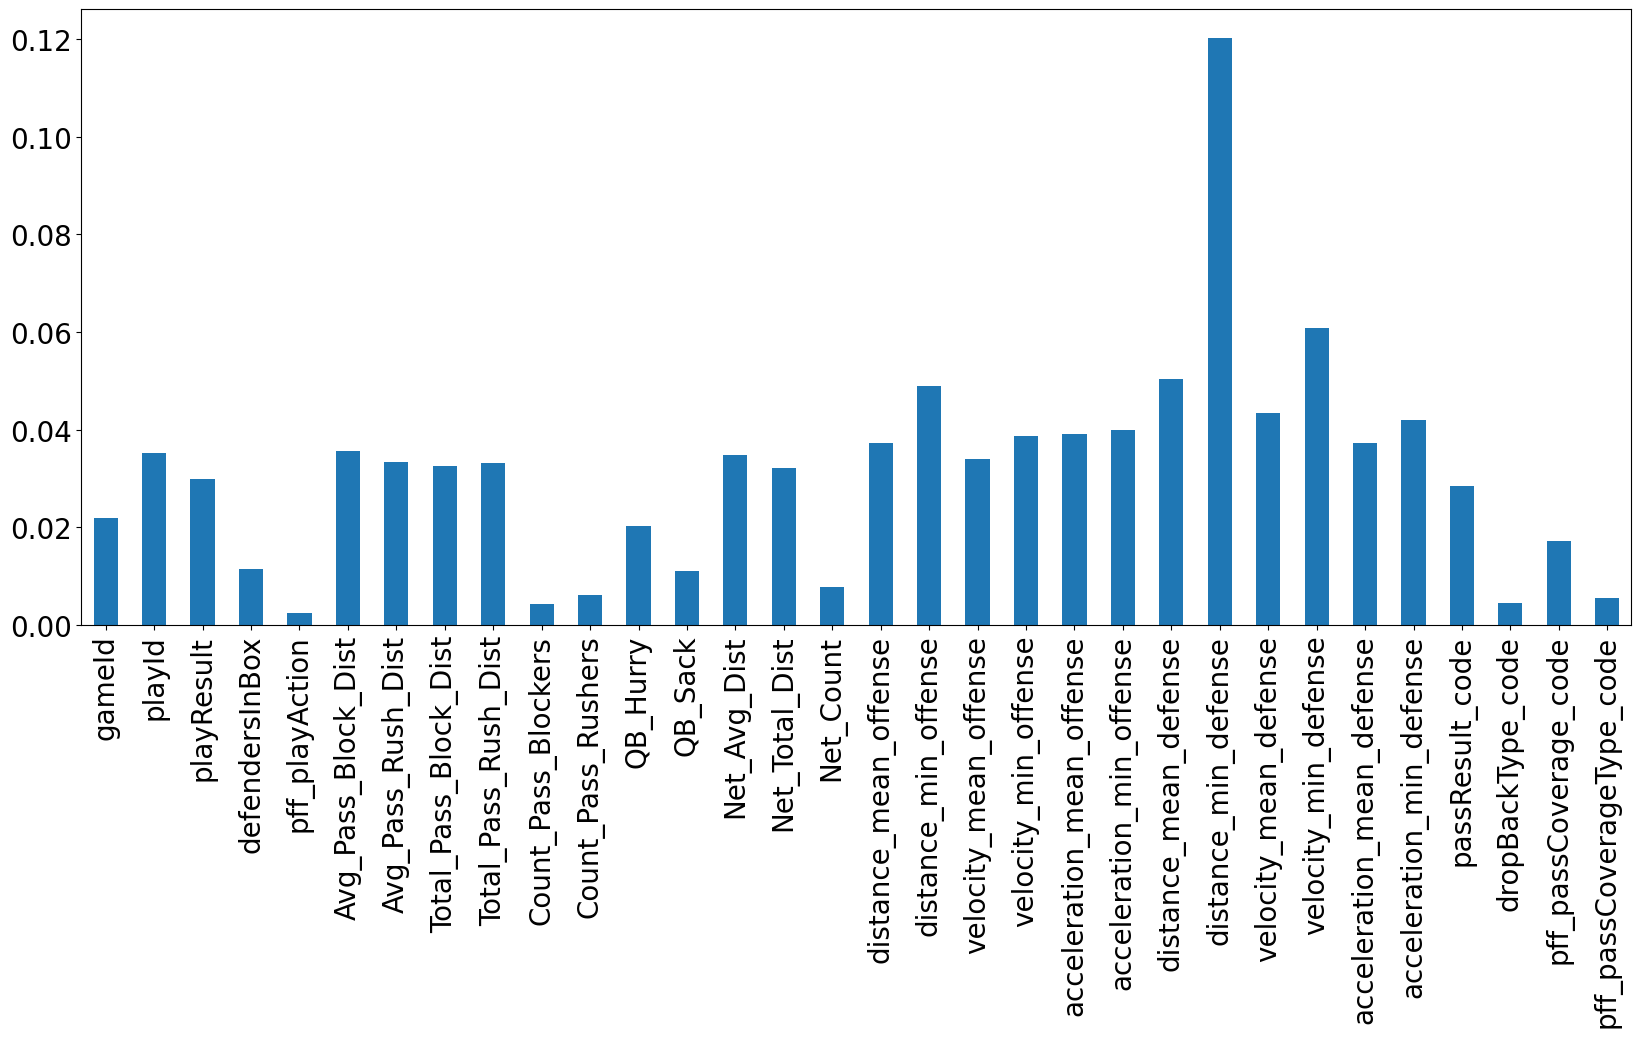

In [18]:
hit_forest_importances = pd.Series(hit_importances, index=X_train.columns) #This makes the feature names the axis labels
hit_forest_importances.plot.bar(fontsize=20, figsize=(20,8))

#### Predicting a sack

**Split data into training and testing sets, create random forest**

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X_sack, y_sack, test_size = 0.2, random_state = 8)

sack_forest = RandomForestClassifier(n_estimators=100) #Creates the forest
sack_forest = sack_forest.fit(X_train,y_train) #Fits the forest to the data

sack_importances = sack_forest.feature_importances_ #Feature importances, note the underscore
sack_importances

array([0.00278697, 0.00360659, 0.36165486, 0.00115274, 0.00064385,
       0.00492143, 0.0051729 , 0.00497999, 0.00453573, 0.00081699,
       0.00149057, 0.00186883, 0.00956908, 0.00439159, 0.00320759,
       0.00122507, 0.00786335, 0.02500251, 0.00590869, 0.01181018,
       0.015548  , 0.00789659, 0.05476936, 0.15156636, 0.00762751,
       0.01117389, 0.01048243, 0.01121829, 0.24711978, 0.01747857,
       0.00168036, 0.00082934])

In [20]:
y_predicted = sack_forest.predict(X_test)
y_predicted

array([0., 1., 0., ..., 0., 0., 0.])

**Confusion matrix, classification report, and feature importance**

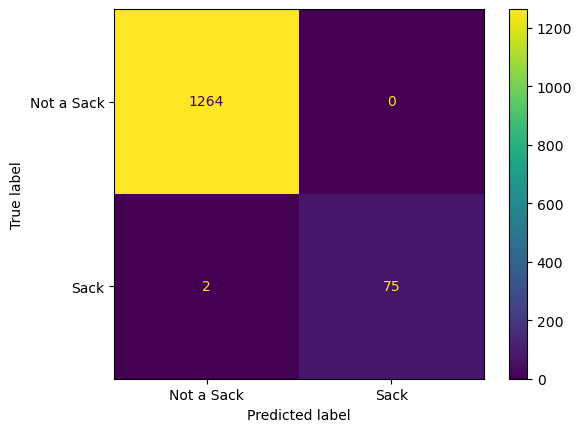

In [21]:
c_sack_matrix = confusion_matrix(y_test,y_predicted)
c_sack_matrix

sack_labels = np.array(['Not a Sack', 'Sack'])
disp = ConfusionMatrixDisplay(confusion_matrix = c_sack_matrix, display_labels = sack_labels)
disp.plot()
plt.show()

In [22]:
sack_class_report = classification_report(y_test, y_predicted, target_names=sack_labels)
print(sack_class_report)

              precision    recall  f1-score   support

  Not a Sack       1.00      1.00      1.00      1264
        Sack       1.00      0.97      0.99        77

    accuracy                           1.00      1341
   macro avg       1.00      0.99      0.99      1341
weighted avg       1.00      1.00      1.00      1341



<Axes: >

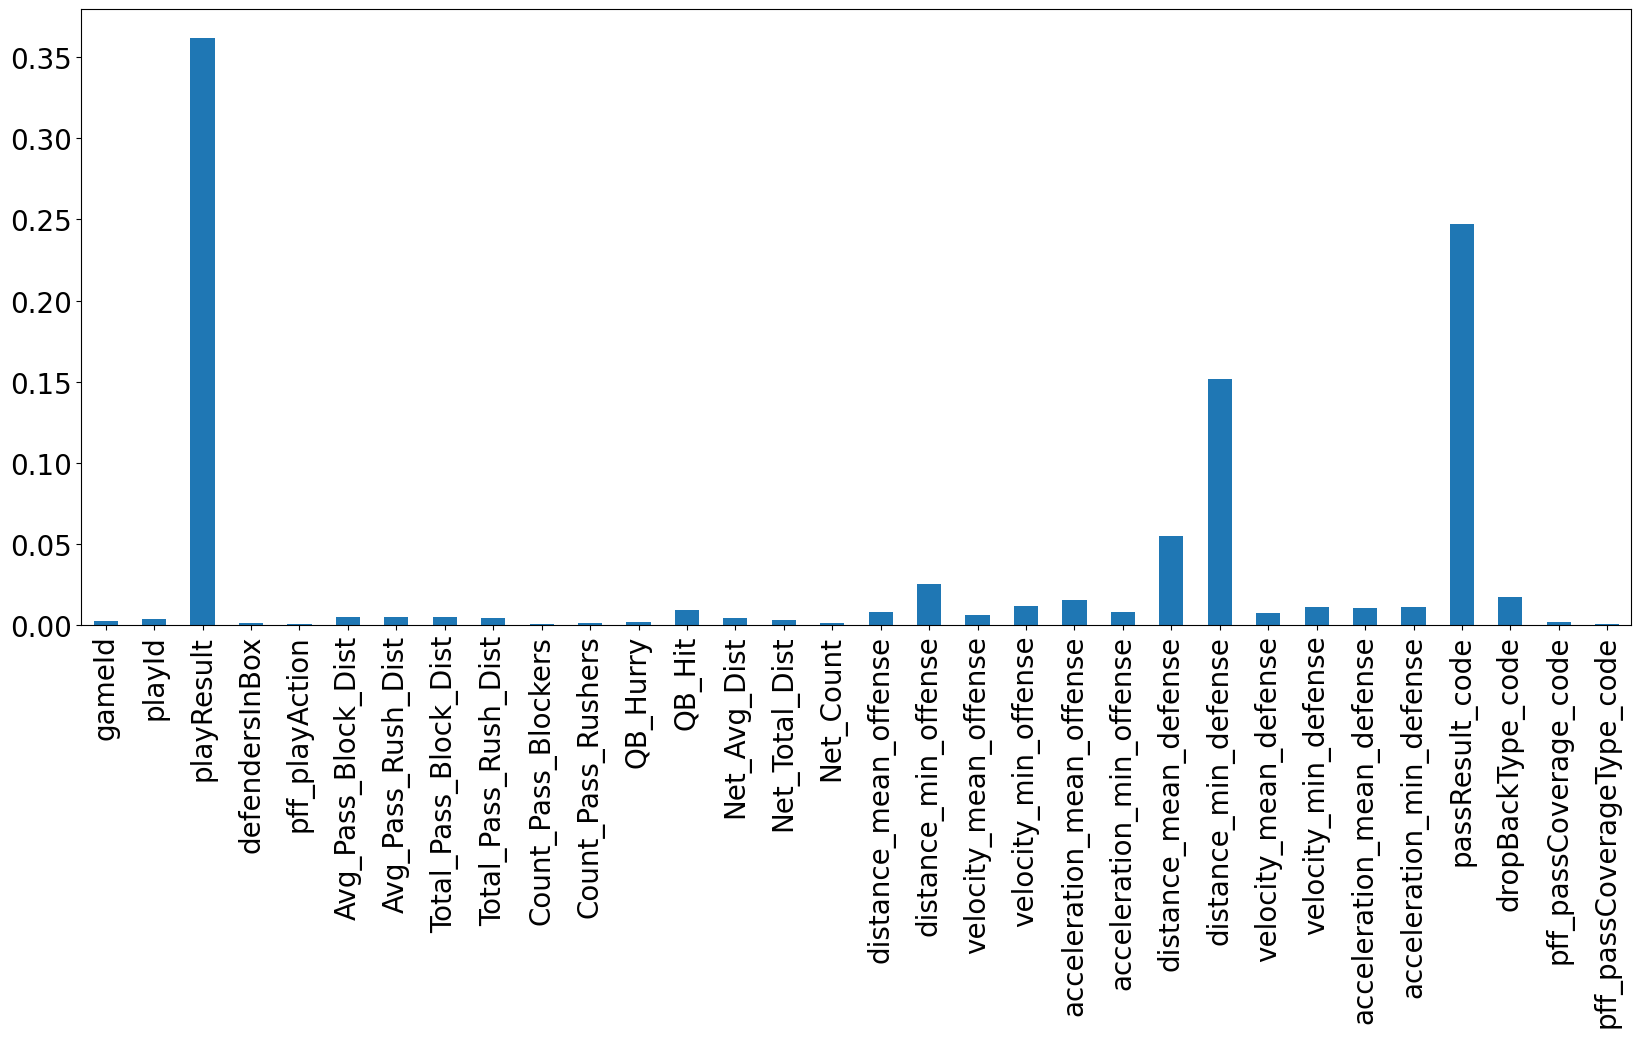

In [23]:
sack_forest_importances = pd.Series(sack_importances, index=X_train.columns) #This makes the feature names the axis labels
sack_forest_importances.plot.bar(fontsize=20, figsize=(20,8))

The result above is a bit unsurprising - if the play result is a negative value, it's quite likely the quarterback got sacked. Let's see how the results change when the playResult is excluded.

#### Predicting whether a play results in a sack without play result

In [24]:
X_sack2 = underscores_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB_Sack', 'playResult'])

X_train, X_test, y_train, y_test = train_test_split(X_sack2, y_sack, test_size = 0.2, random_state = 8)

sack2_forest = RandomForestClassifier(n_estimators=100) #Creates the forest
sack2_forest = sack2_forest.fit(X_train,y_train) #Fits the forest to the data

sack2_importances = sack2_forest.feature_importances_ #Feature importances, note the underscore
sack2_importances

array([0.00546322, 0.00935607, 0.00290415, 0.00112558, 0.00892022,
       0.0100458 , 0.00793495, 0.00923889, 0.00095521, 0.00269715,
       0.00329674, 0.01716137, 0.00829449, 0.00864085, 0.00151559,
       0.01666494, 0.03275828, 0.01528481, 0.01542851, 0.02204283,
       0.01292864, 0.07006918, 0.23623629, 0.017675  , 0.01934   ,
       0.01882812, 0.01571308, 0.36165775, 0.04205281, 0.00427521,
       0.00149427])

In [25]:
y_predicted = sack2_forest.predict(X_test)
y_predicted

array([0., 1., 0., ..., 0., 0., 0.])

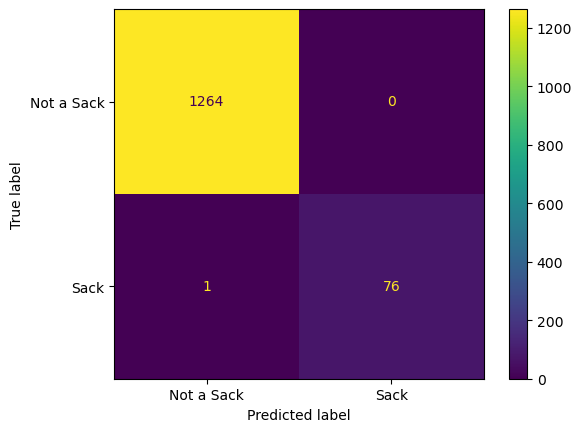

In [26]:
c_sack_matrix = confusion_matrix(y_test,y_predicted)
c_sack_matrix

sack_labels = np.array(['Not a Sack', 'Sack'])
disp = ConfusionMatrixDisplay(confusion_matrix = c_sack_matrix, display_labels = sack_labels)
disp.plot()
plt.show()

<Axes: >

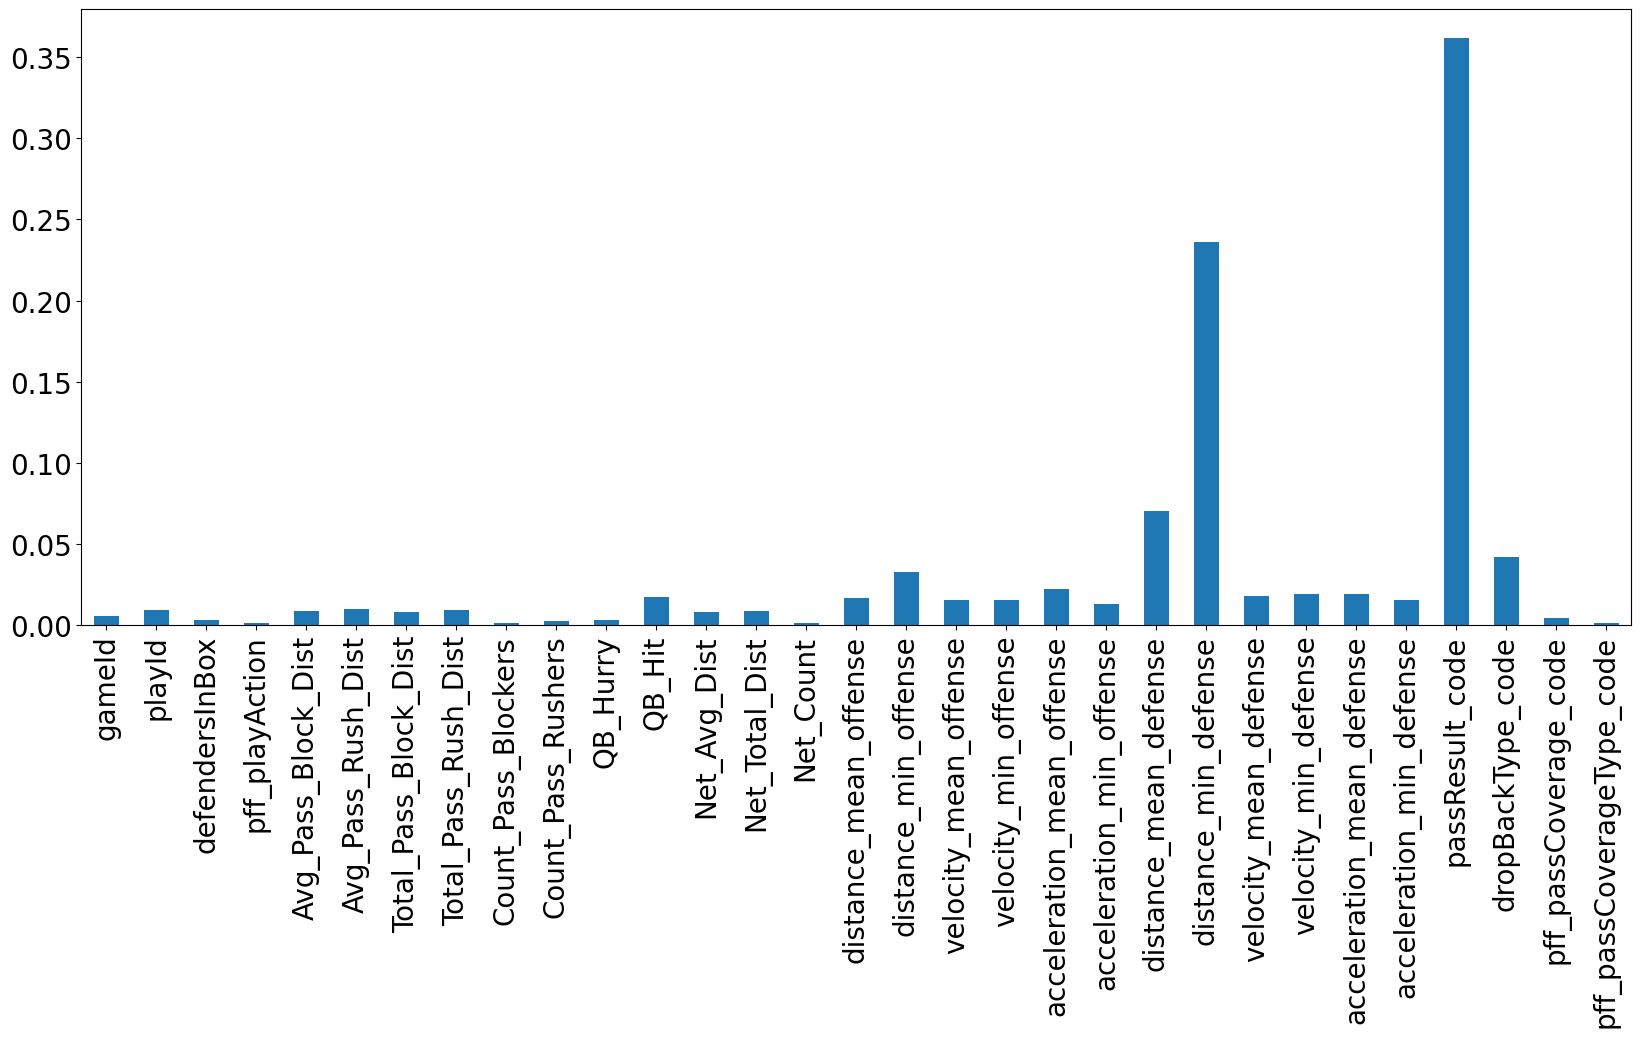

In [27]:
sack2_forest_importances = pd.Series(sack2_importances, index=X_train.columns) #This makes the feature names the axis labels
sack2_forest_importances.plot.bar(fontsize=20, figsize=(20,8))

We'll go one more level down, removing the pass result as well.

#### Predicting whether a play results in a sack without play result and pass result

In [28]:
X_sack3 = underscores_df.drop(columns = ['passResult', 'dropBackType', 'pff_passCoverage', 'pff_passCoverageType', 'QB_Sack', 'playResult', 'passResult_code'])

X_train, X_test, y_train, y_test = train_test_split(X_sack3, y_sack, test_size = 0.2, random_state = 8)

sack3_forest = RandomForestClassifier(n_estimators=100) #Creates the forest
sack3_forest = sack3_forest.fit(X_train,y_train) #Fits the forest to the data

sack3_importances = sack3_forest.feature_importances_ #Feature importances, note the underscore
sack3_importances

array([0.012207  , 0.01918326, 0.00728103, 0.00167671, 0.01973825,
       0.01948649, 0.01791548, 0.01892713, 0.00266039, 0.00450095,
       0.00532129, 0.03028808, 0.01808818, 0.01734667, 0.00359727,
       0.03141753, 0.06318904, 0.02420952, 0.03884699, 0.04330615,
       0.02621025, 0.11698361, 0.29629256, 0.0305886 , 0.03414175,
       0.04036038, 0.02918105, 0.01337641, 0.01007761, 0.00360037])

In [29]:
y_predicted = sack3_forest.predict(X_test)
y_predicted

array([0., 1., 0., ..., 0., 0., 0.])

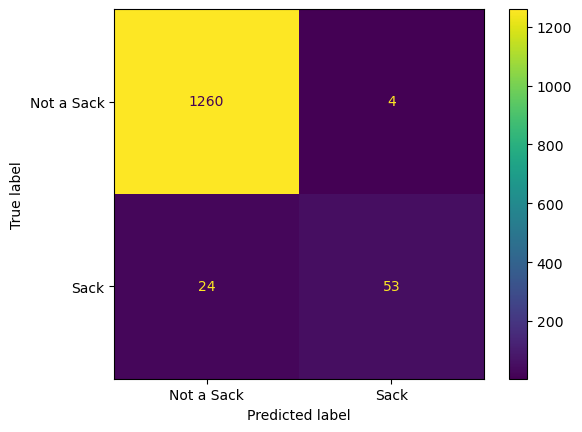

In [30]:
c_sack_matrix = confusion_matrix(y_test,y_predicted)
c_sack_matrix

sack_labels = np.array(['Not a Sack', 'Sack'])
disp = ConfusionMatrixDisplay(confusion_matrix = c_sack_matrix, display_labels = sack_labels)
disp.plot()
plt.show()

In [31]:
sack3_class_report = classification_report(y_test, y_predicted, target_names=sack_labels)
print(sack3_class_report)

              precision    recall  f1-score   support

  Not a Sack       0.98      1.00      0.99      1264
        Sack       0.93      0.69      0.79        77

    accuracy                           0.98      1341
   macro avg       0.96      0.84      0.89      1341
weighted avg       0.98      0.98      0.98      1341



<Axes: >

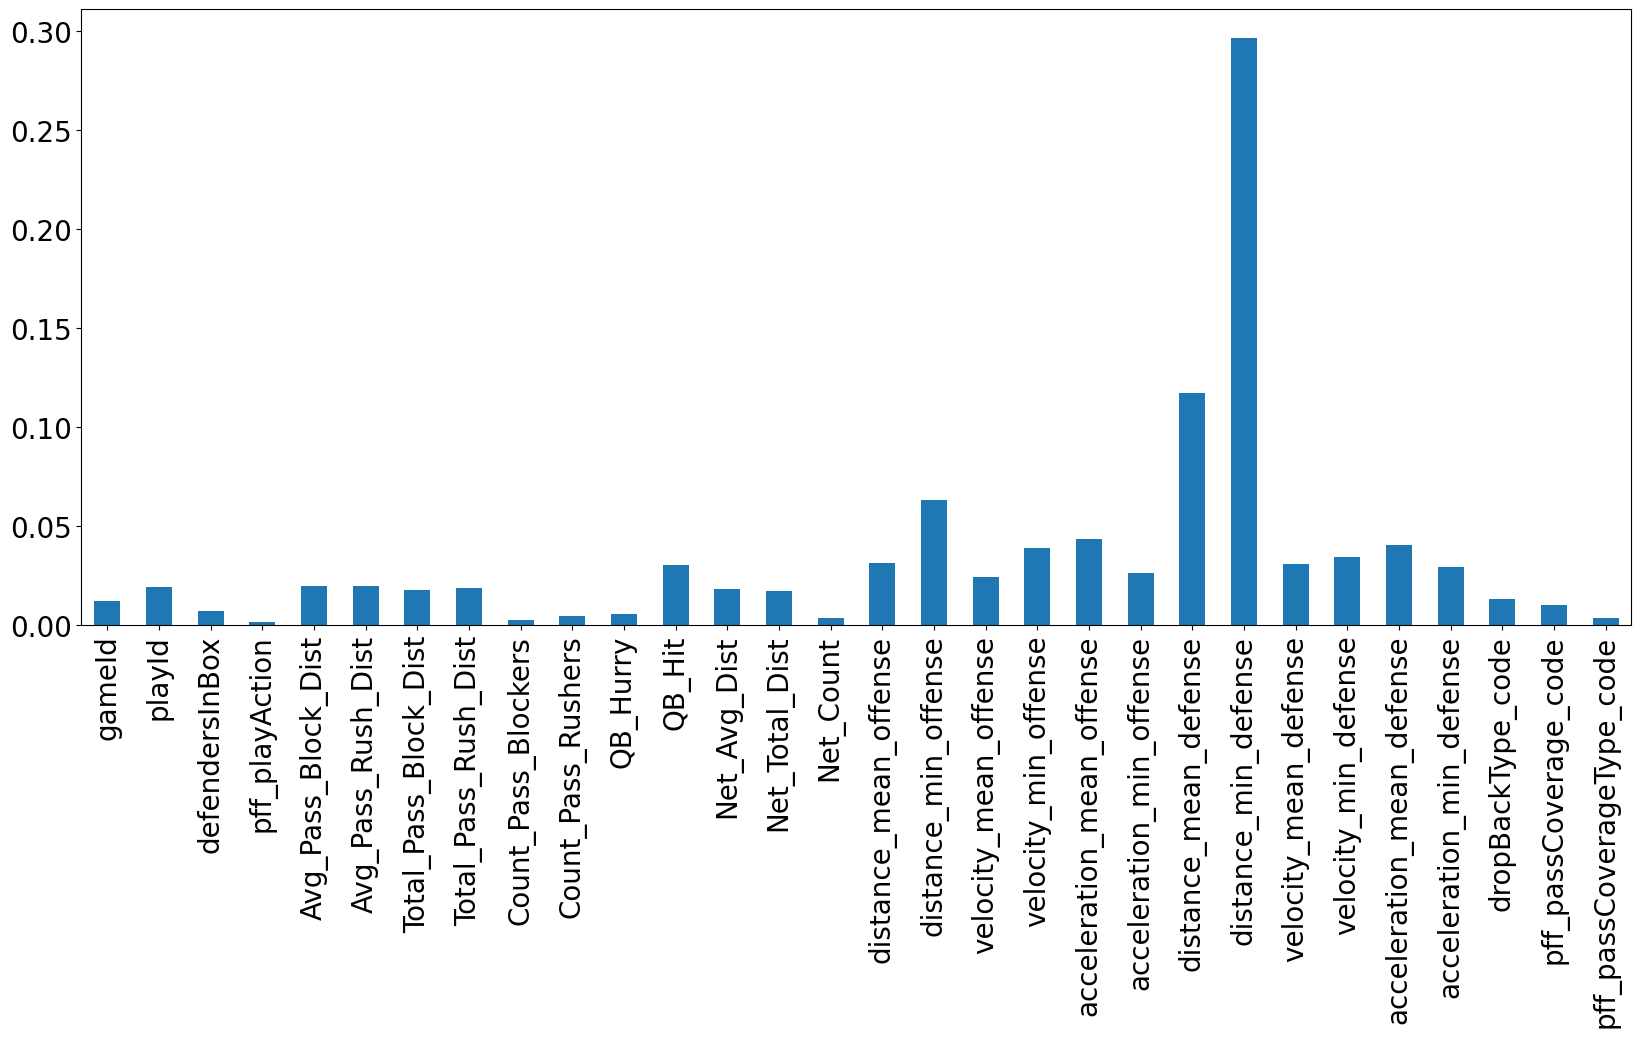

In [32]:
sack3_forest_importances = pd.Series(sack3_importances, index=X_train.columns) #This makes the feature names the axis labels
sack3_forest_importances.plot.bar(fontsize=20, figsize=(20,8))